# NYC Airbnb exploratory data analysis

This notebook inspects the raw sample artifact, missingness, price distribution, NYC coordinate bounds and prices by borough/room type. In submission mode it consumes `sample.csv:latest` inside a W&B EDA run, recording lineage. The supplied executed notebook used the bundled sample locally; these outputs are not a claim that W&B was accessed.

Set `WANDB_ENTITY` in your terminal and run all cells without `NYC_EDA_LOCAL=1` to create your own W&B EDA evidence.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import wandb

local_verification = os.getenv("NYC_EDA_LOCAL") == "1"
run = None
if local_verification:
    sample_path = Path("components/get_data/data/sample1.csv")
    print("LOCAL VERIFICATION: using bundled sample1.csv; no W&B run created.")
else:
    run = wandb.init(project="nyc_airbnb", job_type="eda", group="sample1")
    sample_path = Path(run.use_artifact("sample.csv:latest").file())
df = pd.read_csv(sample_path)
print(f"Rows: {len(df):,}; columns: {len(df.columns)}")
df.head()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/sethgilbert/.netrc.
wandb: Currently logged in as: sethc-gilbert (sethc-gilbert-western-governors-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Rows: 20,000; columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,9138664,Private Lg Room 15 min to Manhattan,47594947,Iris,Queens,Sunnyside,40.74271,-73.92493,Private room,74,2,6,2019-05-26,0.13,1,5
1,31444015,TIME SQUARE CHARMING ONE BED IN HELL'S KITCHEN...,8523790,Johlex,Manhattan,Hell's Kitchen,40.76682,-73.98878,Entire home/apt,170,3,0,NaN,NaN,1,188
2,8741020,Voted #1 Location Quintessential 1BR W Village...,45854238,John,Manhattan,West Village,40.73631,-74.00611,Entire home/apt,245,3,51,2018-09-19,1.12,1,0
3,34602077,Spacious 1 bedroom apartment 15min from Manhattan,261055465,Regan,Queens,Astoria,40.76424,-73.92351,Entire home/apt,125,3,1,2019-05-24,0.65,1,13
4,23203149,Big beautiful bedroom in huge Bushwick apartment,143460,Megan,Brooklyn,Bushwick,40.69839,-73.92044,Private room,65,2,8,2019-06-23,0.52,2,8


In [2]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,20000.0,NaN,NaN,NaN,18923800.78335,11012232.415483,2539.0,9393540.5,19521168.5,29129358.75,36485609.0
name,19993,19768,Brooklyn Apartment,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,20000.0,NaN,NaN,NaN,67460344.0675,78579364.799929,2571.0,7853718.25,31114309.5,106842560.0,274273284.0
host_name,19992,6517,David,170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,20000,5,Manhattan,8774,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,20000,217,Williamsburg,1580,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,20000.0,NaN,NaN,NaN,40.728455,0.054755,40.50873,40.68942,40.72273,40.76299,40.91306
longitude,20000.0,NaN,NaN,NaN,-73.952125,0.046559,-74.23914,-73.98303,-73.95564,-73.93638,-73.71795
room_type,20000,3,Entire home/apt,10384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,20000.0,NaN,NaN,NaN,153.26905,243.325609,0.0,69.0,105.0,175.0,10000.0


In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

last_review          4123
reviews_per_month    4123
host_name               8
name                    7
dtype: int64

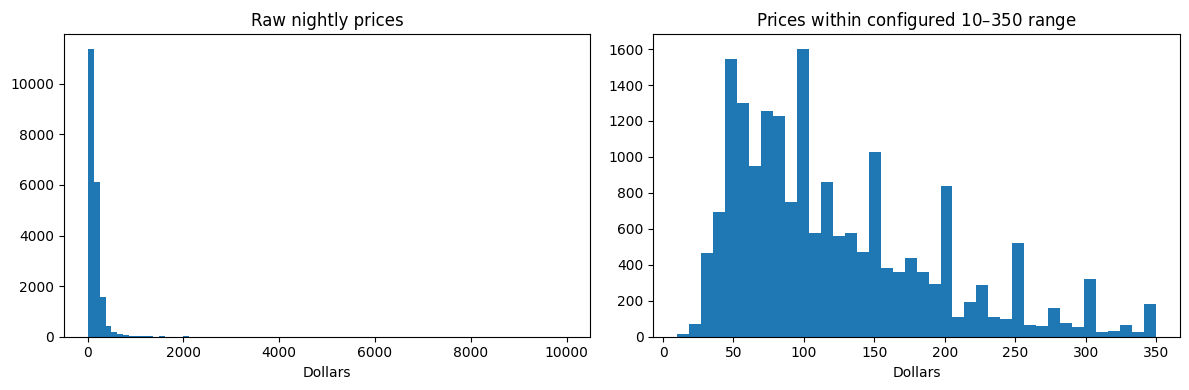

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df.price, bins=80)
axes[0].set_title("Raw nightly prices")
axes[0].set_xlabel("Dollars")
axes[1].hist(df.loc[df.price.between(10, 350), "price"], bins=40)
axes[1].set_title("Prices within configured $10–$350 range")
axes[1].set_xlabel("Dollars")
fig.tight_layout()
if run:
    run.log({"price_distribution": wandb.Image(fig)})
plt.show()

In [5]:
summary = df.groupby(["neighbourhood_group", "room_type"])["price"].agg(["count", "median", "mean"])
summary

count  median        mean
neighbourhood_group room_type                                 
Bronx               Entire home/apt    150   100.0  127.526667
                    Private room       264    55.0   74.382576
                    Shared room         27    36.0   46.962963
Brooklyn            Entire home/apt   3946   147.0  176.617841
                    Private room      4165    65.0   74.796879
                    Shared room        154    36.5   50.902597
Manhattan           Entire home/apt   5335   195.0  253.876851
                    Private room      3257    90.0  119.532699
                    Shared room        182    65.0   82.708791
Queens              Entire home/apt    879   120.0  148.574516
                    Private room      1399    59.0   67.173695
                    Shared room         77    45.0   89.558442
Staten Island       Entire home/apt     74   112.5  177.810811
                    Private room        87    50.0   61.977011
                    Shared room          4    29.5   55.500000

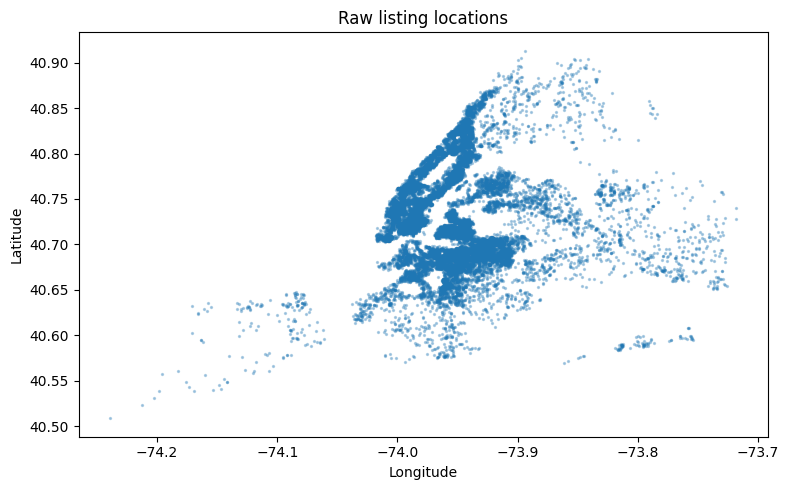

Outside configured NYC bounds: 0
Rows retained by price filter: 19001


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.longitude, df.latitude, s=2, alpha=0.3)
ax.set(xlabel="Longitude", ylabel="Latitude", title="Raw listing locations")
fig.tight_layout()
if run:
    run.log({"listing_locations": wandb.Image(fig)})
plt.show()
inside = df.longitude.between(-74.25, -73.50) & df.latitude.between(40.5, 41.2)
print("Outside configured NYC bounds:", int((~inside).sum()))
print("Rows retained by price filter:", int(df.price.between(10, 350).sum()))

## Findings and modeling choices

Prices have a long right tail, so the pipeline focuses on listings priced between $10 and $350 per night as configured. The first sample contains 20,000 raw records and 19,001 records after this price filter. This narrows the model's intended use and excludes high-price luxury properties.

Review dates and reviews per month are missing for properties without reviews; titles and host names also contain missing values. The preprocessing pipeline imputes numeric values, missing review dates and titles, encodes room type and borough, and extracts a small title vocabulary. Host names and listing identifiers are dropped because they are not useful generalizable price predictors.

The train/test and train/validation splits are stratified by borough. Preprocessing is fit on training rows only. Random Forest hyperparameters are compared using validation MAE; the held-out test set is reserved for the selected model. Review-date reference values are learned from training data so predictions for a record do not change with its inference batch.

The second sample's out-of-area row is intentionally not removed in release 1.0.0; the geographic data check must expose it before release 1.0.1 adds filtering. Model performance remains a historical within-dataset estimate, not proof of accuracy on future rental markets.

In [7]:
if run:
    run.summary.update({"raw_rows": len(df), "raw_columns": len(df.columns),
                        "price_filter_rows": int(df.price.between(10, 350).sum()),
                        "outside_nyc_rows": int((~inside).sum())})
    run.finish()

outside_nyc_rows,0
price_filter_rows,19001
raw_columns,16
raw_rows,20000
